<a href="https://colab.research.google.com/github/nathancdy/460-Lab-10/blob/main/DEAP_image_evolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Evolution with DEAP

## Setup and Imports

In [1]:
! pip install deap numpy matplotlib ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 983.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 25.8 MB/s eta 0:00:00


In [2]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms
import random
import time

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Display settings for better visualization
plt.rcParams['figure.figsize'] = (12, 6)

## Create Target Image Function

Let's generate our target image as a size and shape

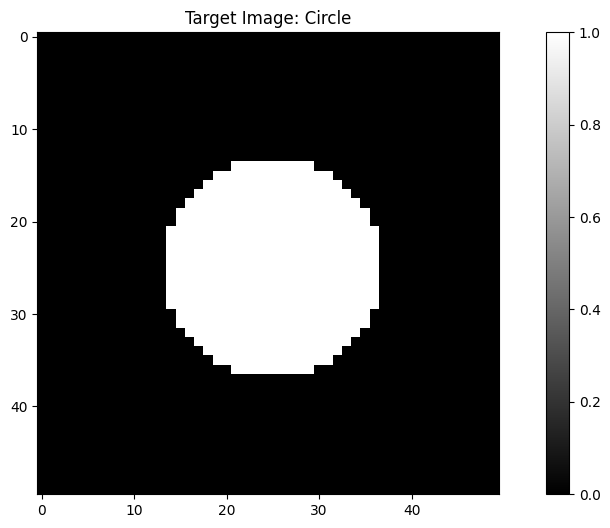

In [3]:
def create_target_image(size=50, shape="circle"):
    """
    Create a target image for evolution to match.

    Parameters:
    - size: Size of the square image in pixels
    - shape: Type of shape ("circle", "square", "triangle", or "cross")

    Returns:
    - 2D numpy array representing the image
    """
    image = np.zeros((size, size))
    center = size // 2
    radius = size // 4

    if shape == "circle":
        for i in range(size):
            for j in range(size):
                if (i - center)**2 + (j - center)**2 < radius**2:
                    image[i, j] = 1

    elif shape == "square":
        start = center - radius
        end = center + radius
        image[start:end, start:end] = 1

    elif shape == "triangle":
        height = 2 * radius
        for i in range(size):
            for j in range(size):
                # Check if point is inside an equilateral triangle
                if (i >= center - height/2) and (i <= center + height/2) and \
                   (j >= center - radius) and (j <= center + radius) and \
                   (i + j >= 2*center - radius):
                    image[i, j] = 1

    elif shape == "cross":
        thickness = radius // 2
        # Horizontal bar
        image[center-thickness:center+thickness, center-radius:center+radius] = 1
        # Vertical bar
        image[center-radius:center+radius, center-thickness:center+thickness] = 1

    return image

# Create and display target image
shape_type = "circle"  # Try different shapes: "circle", "square", "triangle", "cross"
target_image = create_target_image(size=50, shape=shape_type)

plt.figure()
plt.imshow(target_image, cmap='gray')
plt.title(f"Target Image: {shape_type.capitalize()}")
plt.colorbar()
plt.show()

## Genetic Algorithm Setup - Fitness and Individual Definition

Define a "Individual" represented by an array of pixels, and a fitness function that minimizes the difference from our target image

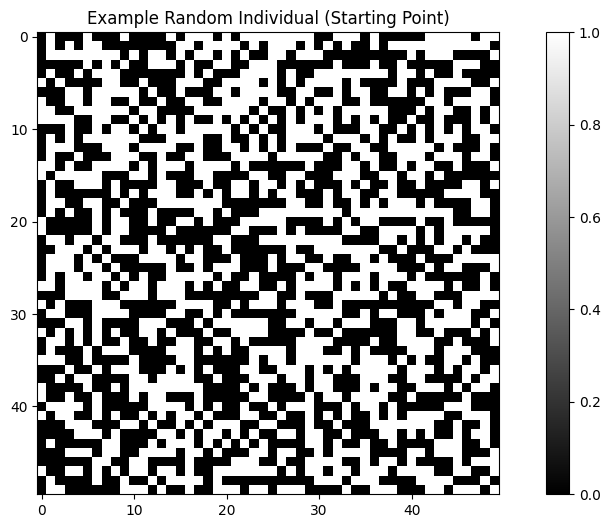

In [4]:
# Clear any previous creator settings to avoid errors if re-running
if 'FitnessMin' in creator.__dict__:
    del creator.FitnessMin
    del creator.Individual

# Define fitness (minimize difference from target)
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", np.ndarray, fitness=creator.FitnessMin)

# Initialize toolbox
toolbox = base.Toolbox()

def create_random_image(size=50):
    """Generate a random binary image"""
    return np.random.randint(0, 2, (size, size))

# Register creation functions
toolbox.register("individual", tools.initIterate, creator.Individual, create_random_image)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Generate and display a random individual
random_individual = toolbox.individual()
plt.figure()
plt.imshow(random_individual, cmap='gray')
plt.title("Example Random Individual (Starting Point)")
plt.colorbar()
plt.show()

## Define Fitness Function and Genetic Operators

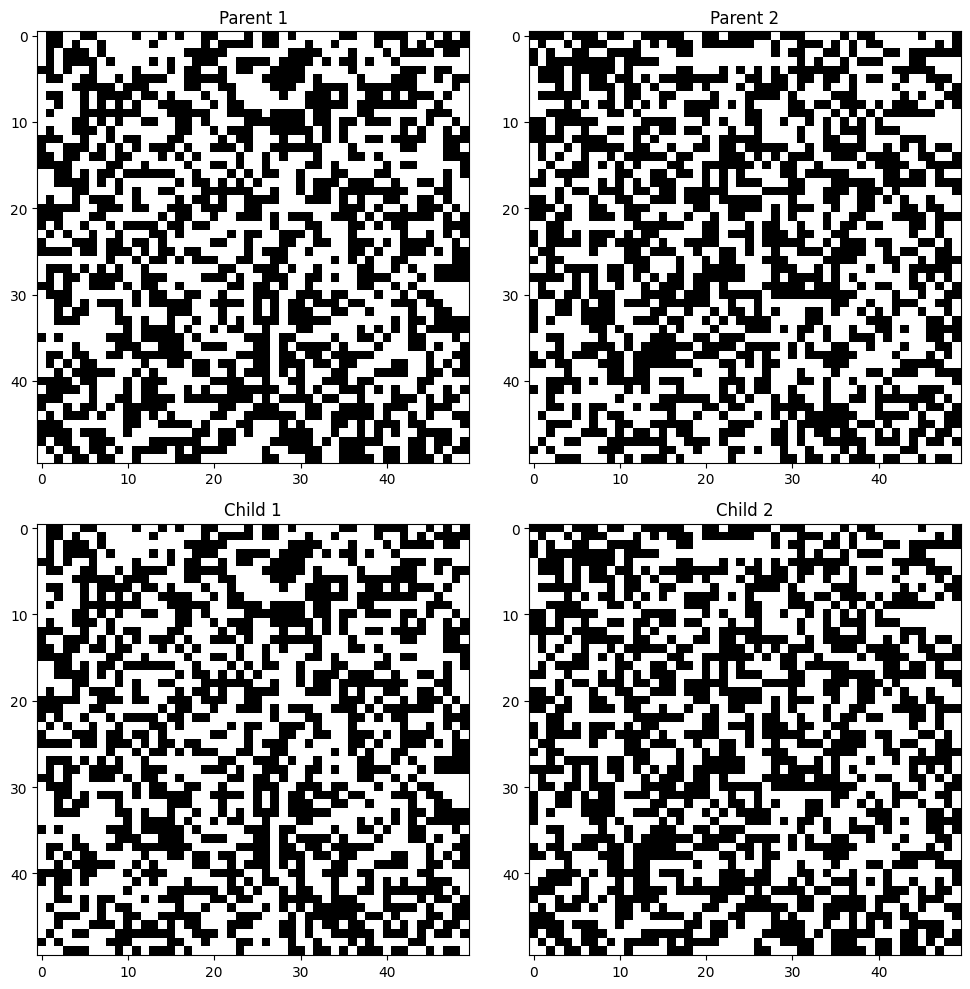

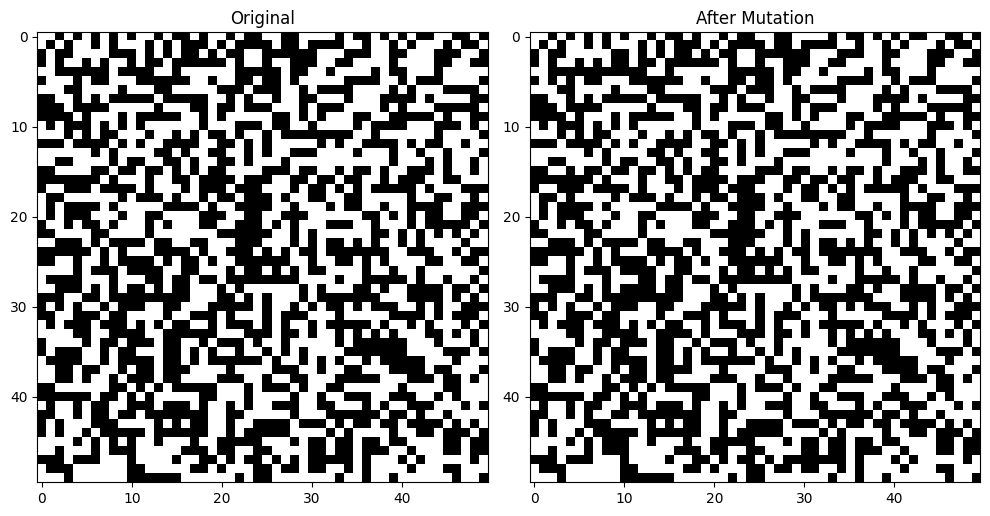

In [5]:
# Fitness function: Mean squared error between images
def evaluate_image(individual):
    """Calculate fitness as MSE between individual and target image"""
    mse = np.sum((individual - target_image) ** 2) / (individual.shape[0] * individual.shape[1])
    return mse,

# Register the evaluation function
toolbox.register("evaluate", evaluate_image)

# Custom crossover: Single point spatial crossover
def image_crossover(ind1, ind2):
    """
    Perform spatial crossover between two images.
    Randomly chooses a row to split the images and swaps parts.
    """
    size = ind1.shape[0]
    # Choose a row to split
    split_point = random.randint(1, size-1)

    # Create offspring (need to create proper Individual objects)
    offspring1 = creator.Individual(np.vstack((ind1[:split_point].copy(), ind2[split_point:].copy())))
    offspring2 = creator.Individual(np.vstack((ind2[:split_point].copy(), ind1[split_point:].copy())))

    return offspring1, offspring2

# Test crossover
parent1 = toolbox.individual()
parent2 = toolbox.individual()
child1, child2 = image_crossover(parent1, parent2)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(parent1, cmap='gray')
axes[0, 0].set_title("Parent 1")
axes[0, 1].imshow(parent2, cmap='gray')
axes[0, 1].set_title("Parent 2")
axes[1, 0].imshow(child1, cmap='gray')
axes[1, 0].set_title("Child 1")
axes[1, 1].imshow(child2, cmap='gray')
axes[1, 1].set_title("Child 2")
plt.tight_layout()
plt.show()

# Custom mutation: Flip pixels with a certain probability
def image_mutation(individual, indpb=0.01):
    """
    Mutate an image by randomly flipping pixels with probability indpb.

    Parameters:
    - individual: The image to mutate
    - indpb: Independent probability of each pixel being flipped
    """
    # Create a copy to avoid modifying the original
    result = individual.copy()

    for i in range(result.shape[0]):
        for j in range(result.shape[1]):
            if random.random() < indpb:
                result[i, j] = 1 - result[i, j]  # Flip the pixel

    # Return result properly wrapped as Individual
    return creator.Individual(result),

# Register genetic operators
toolbox.register("mate", image_crossover)
toolbox.register("mutate", image_mutation, indpb=0.01)
toolbox.register("select", tools.selTournament, tournsize=3)

# Test mutation
original = toolbox.individual()
mutated, = image_mutation(original)  # Note: This returns a tuple, so we unpack it

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(original, cmap='gray')
axes[0].set_title("Original")
axes[1].imshow(mutated, cmap='gray')
axes[1].set_title("After Mutation")
plt.tight_layout()
plt.show()

## Define Visualization and Statistics Functions

In [6]:
# Function to visualize the best individual from a population
def plot_best_individual(population, gen, show_fitness_history=False):
    """
    Plot the best individual from a population alongside the target image.

    Parameters:
    - population: Current population of individuals
    - gen: Current generation number
    - show_fitness_history: Whether to plot fitness history graph
    """
    best_ind = tools.selBest(population, 1)[0]
    fitness = best_ind.fitness.values[0]

    if show_fitness_history:
        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1)
    else:
        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)

    plt.imshow(target_image, cmap='gray')
    plt.title("Target Image")
    plt.colorbar()

    if show_fitness_history:
        plt.subplot(1, 3, 2)
    else:
        plt.subplot(1, 2, 2)

    plt.imshow(best_ind, cmap='gray')
    plt.title(f"Generation {gen}, Fitness: {fitness:.4f}")
    plt.colorbar()

    if show_fitness_history and hasattr(plot_best_individual, 'fitness_history'):
        plt.subplot(1, 3, 3)
        plt.plot(plot_best_individual.fitness_history)
        plt.title("Best Fitness Over Generations")
        plt.xlabel("Generation")
        plt.ylabel("Fitness (lower is better)")
        plt.grid(True)

    plt.tight_layout()
    plt.show()

# Function to display a grid of individuals
def plot_population_sample(population, gen, sample_size=9):
    """
    Plot a sample of individuals from the population.

    Parameters:
    - population: Current population of individuals
    - gen: Current generation number
    - sample_size: Number of individuals to display
    """
    # Use top individuals for visualization
    individuals = tools.selBest(population, sample_size)

    # Calculate grid dimensions
    grid_size = int(np.ceil(np.sqrt(sample_size)))

    plt.figure(figsize=(12, 12))
    for i, ind in enumerate(individuals):
        if i >= sample_size:
            break

        plt.subplot(grid_size, grid_size, i+1)
        plt.imshow(ind, cmap='gray')
        plt.title(f"Fitness: {ind.fitness.values[0]:.4f}")
        plt.axis('off')

    plt.suptitle(f"Population Sample - Generation {gen}")
    plt.tight_layout()
    plt.show()

## Run the Genetic Algorithm

Gen 0: Min=0.4776, Avg=0.4932


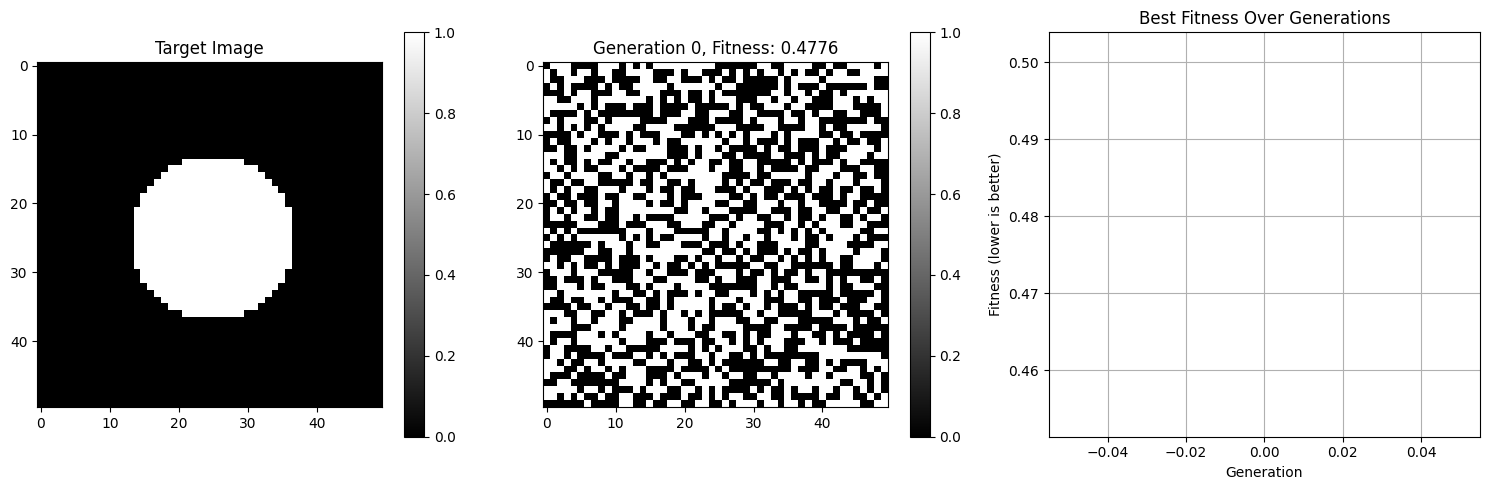

Gen 1: Min=0.4724, Avg=0.4867
Gen 2: Min=0.4700, Avg=0.4793
Gen 3: Min=0.4644, Avg=0.4748
Gen 4: Min=0.4636, Avg=0.4714
Gen 5: Min=0.4636, Avg=0.4679
Gen 6: Min=0.4604, Avg=0.4642
Gen 7: Min=0.4564, Avg=0.4612
Gen 8: Min=0.4540, Avg=0.4588
Gen 9: Min=0.4516, Avg=0.4563
Gen 10: Min=0.4508, Avg=0.4532


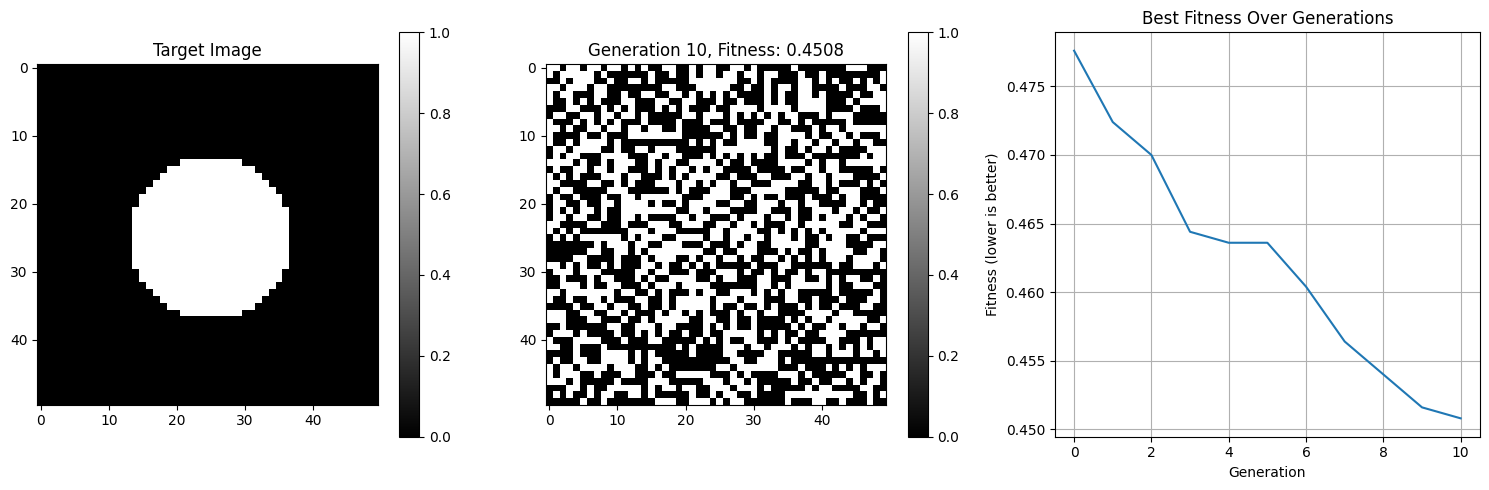

Gen 11: Min=0.4472, Avg=0.4514
Gen 12: Min=0.4468, Avg=0.4500
Gen 13: Min=0.4452, Avg=0.4484
Gen 14: Min=0.4432, Avg=0.4465
Gen 15: Min=0.4432, Avg=0.4452
Gen 16: Min=0.4420, Avg=0.4438
Gen 17: Min=0.4400, Avg=0.4424
Gen 18: Min=0.4384, Avg=0.4413
Gen 19: Min=0.4384, Avg=0.4402
Gen 20: Min=0.4364, Avg=0.4393


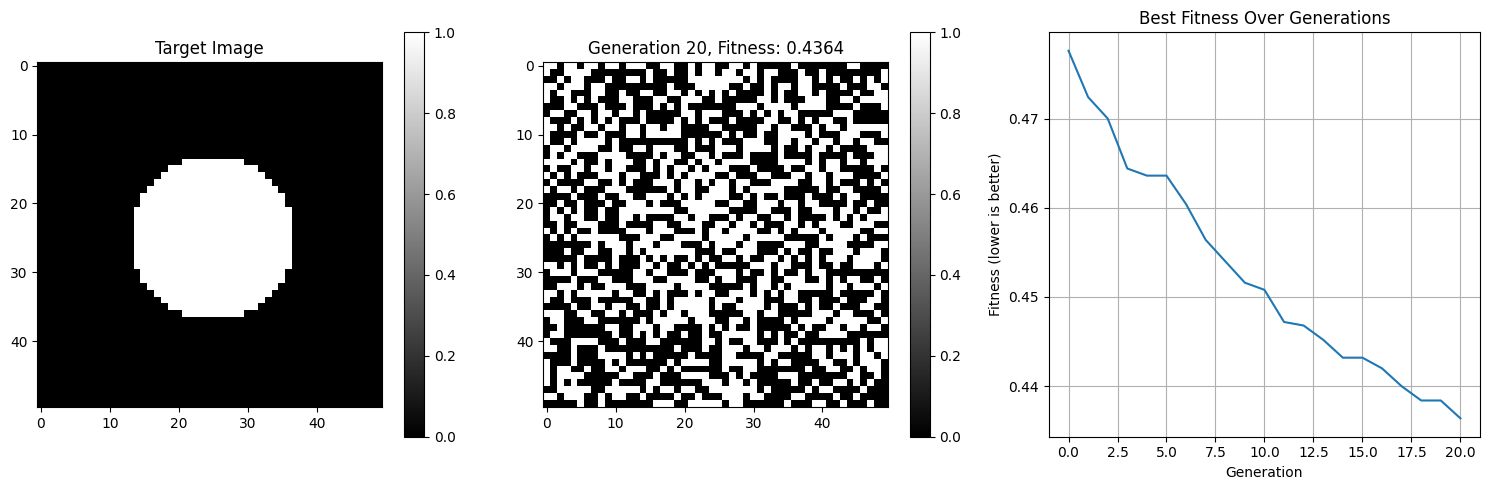

Gen 21: Min=0.4352, Avg=0.4382
Gen 22: Min=0.4336, Avg=0.4372
Gen 23: Min=0.4324, Avg=0.4359
Gen 24: Min=0.4324, Avg=0.4350
Gen 25: Min=0.4316, Avg=0.4334
Gen 26: Min=0.4304, Avg=0.4322
Gen 27: Min=0.4284, Avg=0.4308
Gen 28: Min=0.4248, Avg=0.4292
Gen 29: Min=0.4244, Avg=0.4274
Gen 30: Min=0.4244, Avg=0.4263


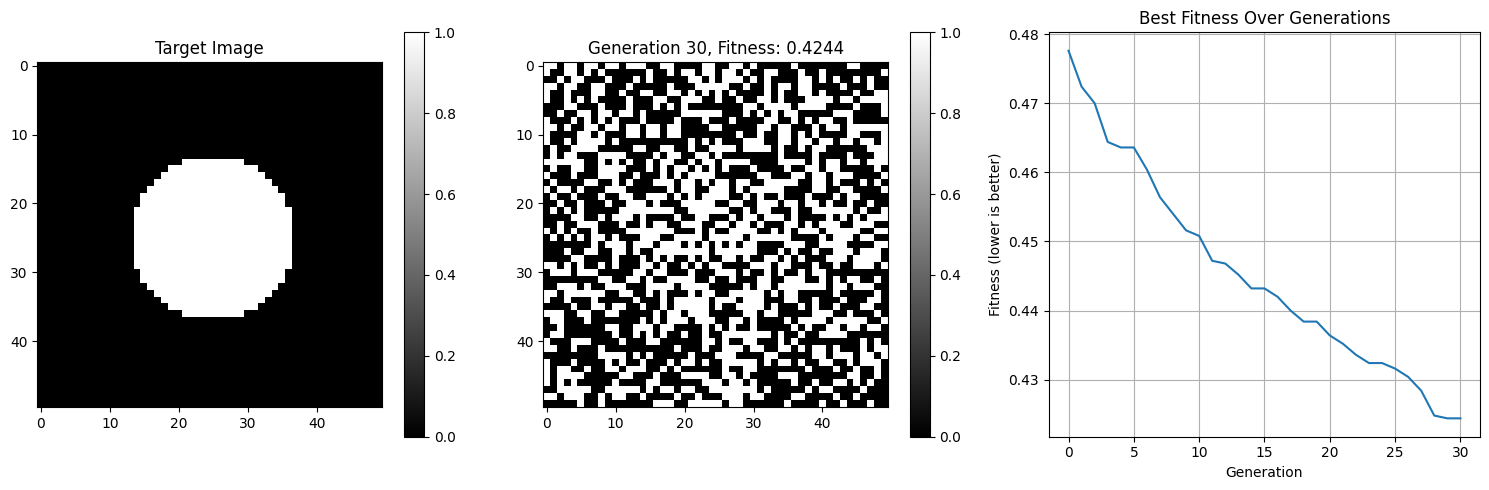

Gen 31: Min=0.4216, Avg=0.4249
Gen 32: Min=0.4216, Avg=0.4237
Gen 33: Min=0.4200, Avg=0.4226
Gen 34: Min=0.4192, Avg=0.4213
Gen 35: Min=0.4180, Avg=0.4204
Gen 36: Min=0.4160, Avg=0.4195
Gen 37: Min=0.4136, Avg=0.4186
Gen 38: Min=0.4136, Avg=0.4173
Gen 39: Min=0.4136, Avg=0.4163
Gen 40: Min=0.4120, Avg=0.4146


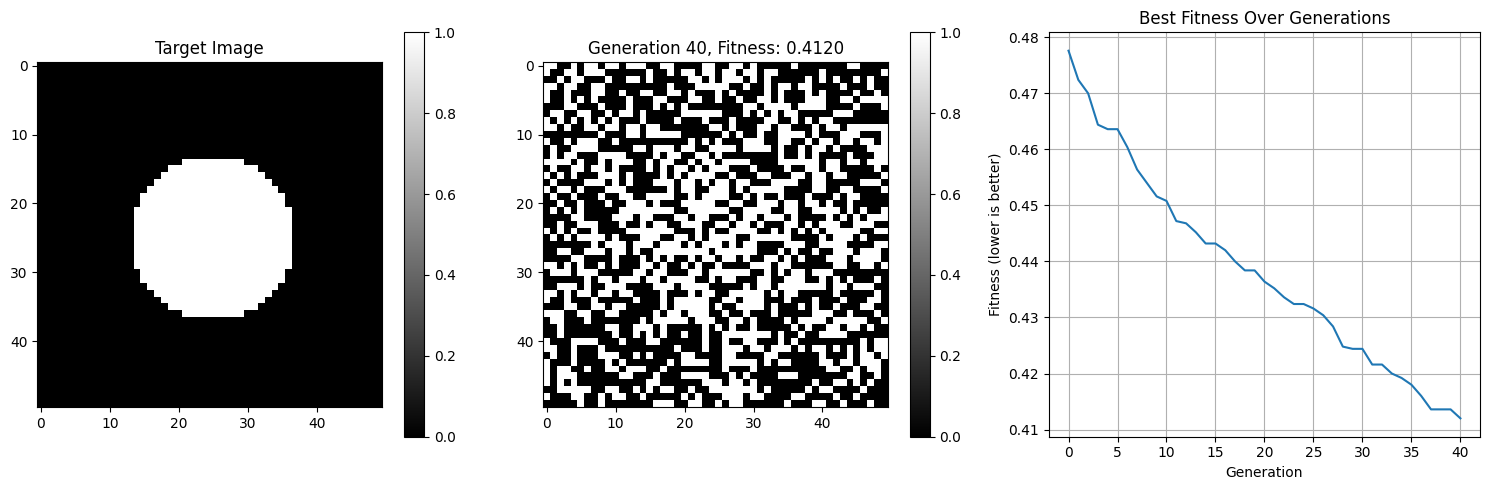

Gen 41: Min=0.4080, Avg=0.4131
Gen 42: Min=0.4088, Avg=0.4120
Gen 43: Min=0.4088, Avg=0.4113
Gen 44: Min=0.4080, Avg=0.4101
Gen 45: Min=0.4056, Avg=0.4090
Gen 46: Min=0.4052, Avg=0.4078
Gen 47: Min=0.4052, Avg=0.4070
Gen 48: Min=0.4044, Avg=0.4062
Gen 49: Min=0.4036, Avg=0.4052
Gen 50: Min=0.4020, Avg=0.4044


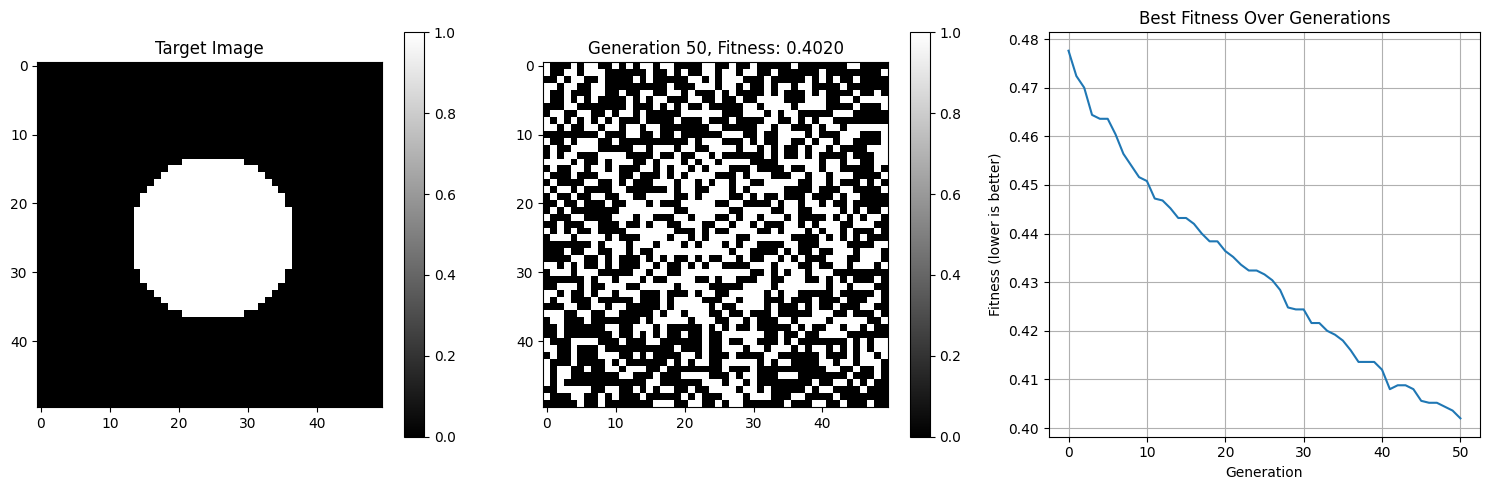

Gen 51: Min=0.4016, Avg=0.4033
Gen 52: Min=0.4008, Avg=0.4023
Gen 53: Min=0.4000, Avg=0.4015
Gen 54: Min=0.4000, Avg=0.4011
Gen 55: Min=0.3992, Avg=0.4006
Gen 56: Min=0.3976, Avg=0.3994
Gen 57: Min=0.3960, Avg=0.3987
Gen 58: Min=0.3960, Avg=0.3976
Gen 59: Min=0.3900, Avg=0.3965
Gen 60: Min=0.3912, Avg=0.3957


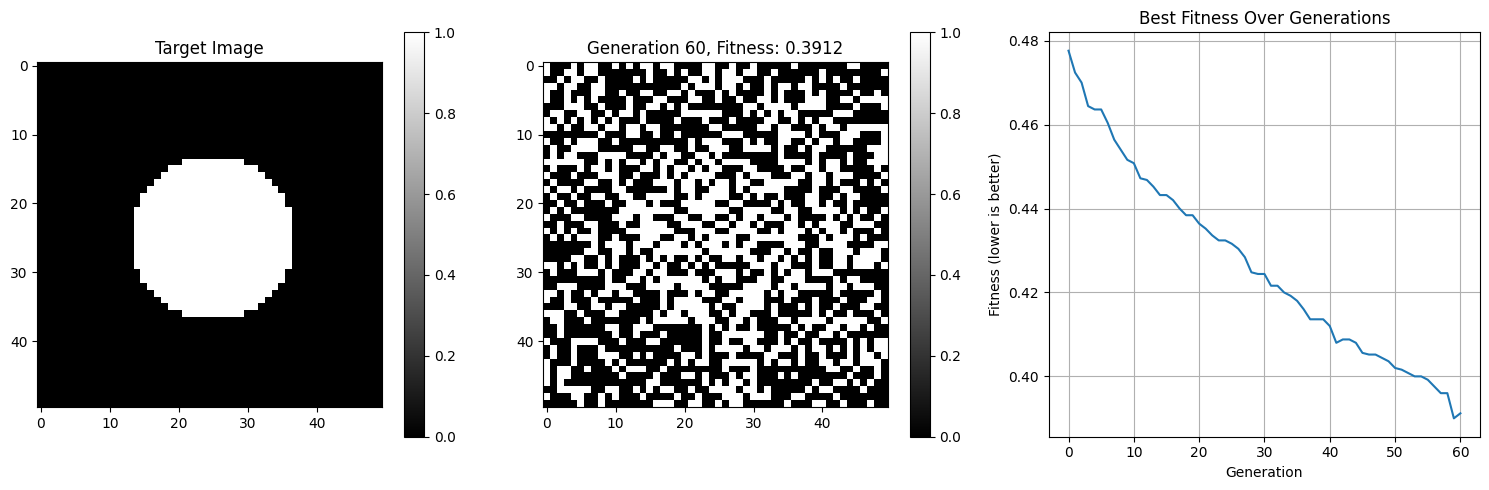

Gen 61: Min=0.3904, Avg=0.3944
Gen 62: Min=0.3904, Avg=0.3929
Gen 63: Min=0.3904, Avg=0.3916
Gen 64: Min=0.3888, Avg=0.3906
Gen 65: Min=0.3868, Avg=0.3897
Gen 66: Min=0.3844, Avg=0.3887
Gen 67: Min=0.3844, Avg=0.3870
Gen 68: Min=0.3840, Avg=0.3859
Gen 69: Min=0.3812, Avg=0.3847
Gen 70: Min=0.3824, Avg=0.3841


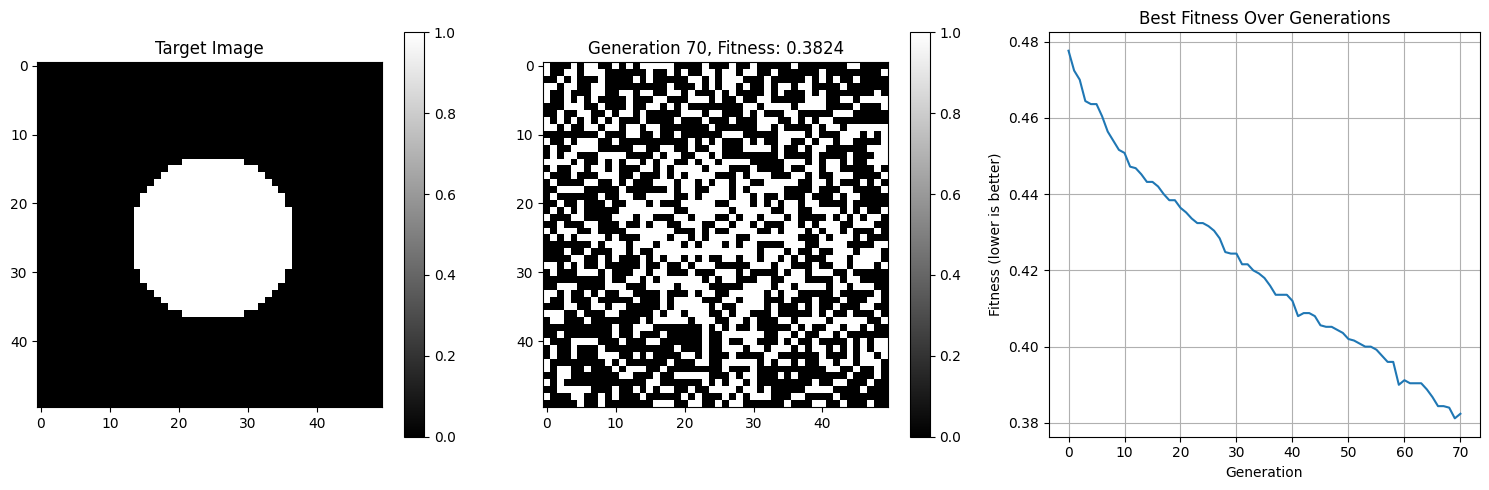

Gen 71: Min=0.3816, Avg=0.3833
Gen 72: Min=0.3816, Avg=0.3828
Gen 73: Min=0.3808, Avg=0.3822
Gen 74: Min=0.3800, Avg=0.3814
Gen 75: Min=0.3792, Avg=0.3807
Gen 76: Min=0.3784, Avg=0.3800
Gen 77: Min=0.3780, Avg=0.3793
Gen 78: Min=0.3768, Avg=0.3785
Gen 79: Min=0.3748, Avg=0.3776
Gen 80: Min=0.3740, Avg=0.3764


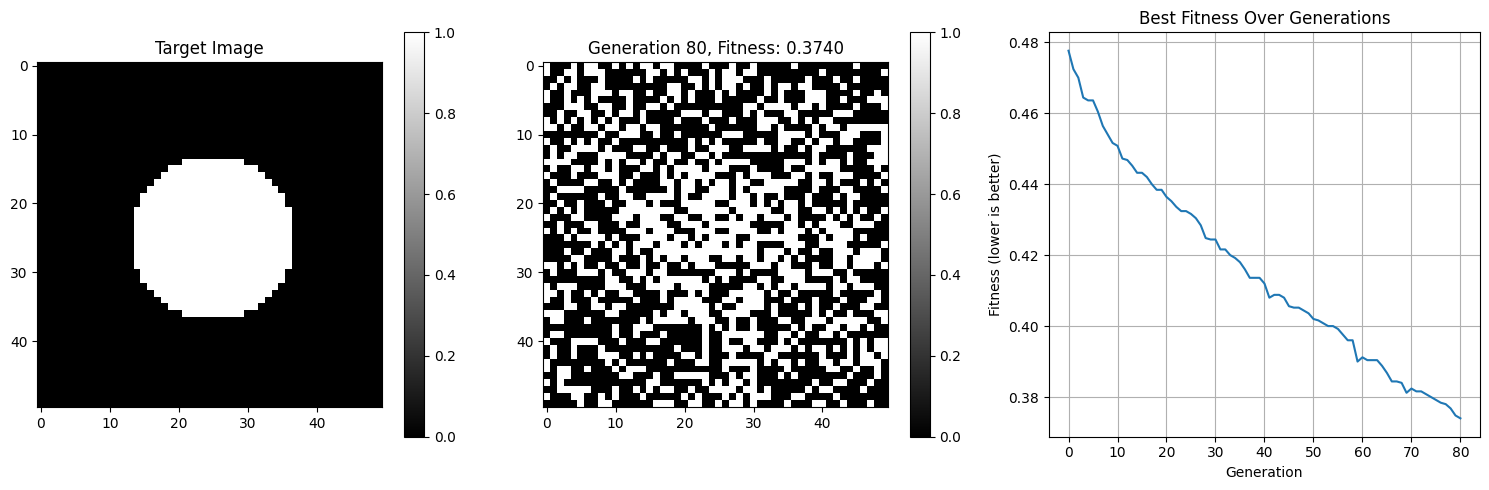

Gen 81: Min=0.3728, Avg=0.3760
Gen 82: Min=0.3728, Avg=0.3750
Gen 83: Min=0.3720, Avg=0.3743
Gen 84: Min=0.3720, Avg=0.3734
Gen 85: Min=0.3696, Avg=0.3725
Gen 86: Min=0.3688, Avg=0.3716
Gen 87: Min=0.3688, Avg=0.3709
Gen 88: Min=0.3684, Avg=0.3701
Gen 89: Min=0.3680, Avg=0.3692
Gen 90: Min=0.3680, Avg=0.3686


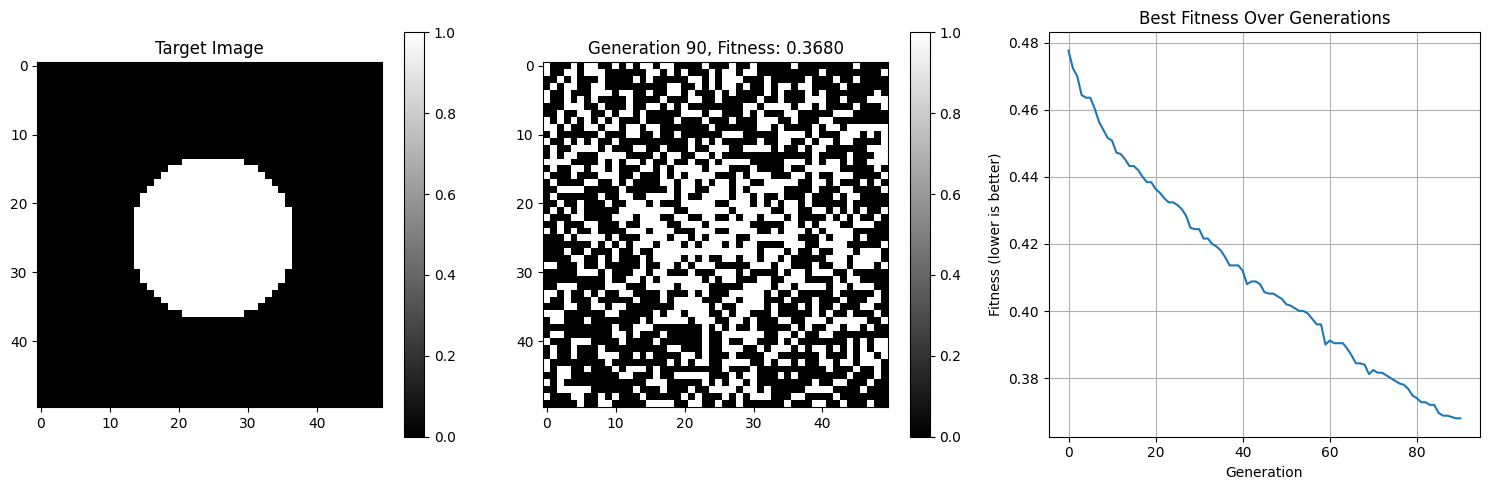

Gen 91: Min=0.3664, Avg=0.3681
Gen 92: Min=0.3664, Avg=0.3677
Gen 93: Min=0.3656, Avg=0.3670
Gen 94: Min=0.3656, Avg=0.3664
Gen 95: Min=0.3636, Avg=0.3655
Gen 96: Min=0.3632, Avg=0.3648
Gen 97: Min=0.3624, Avg=0.3639
Gen 98: Min=0.3596, Avg=0.3630
Gen 99: Min=0.3604, Avg=0.3618


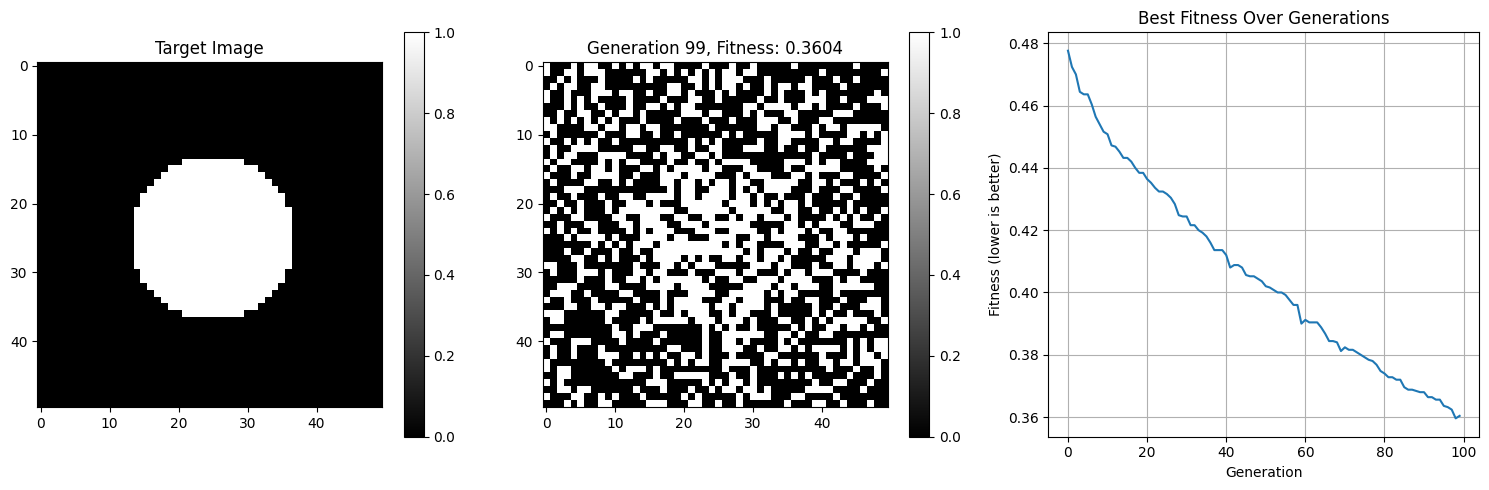

Evolution completed in 4.78 seconds


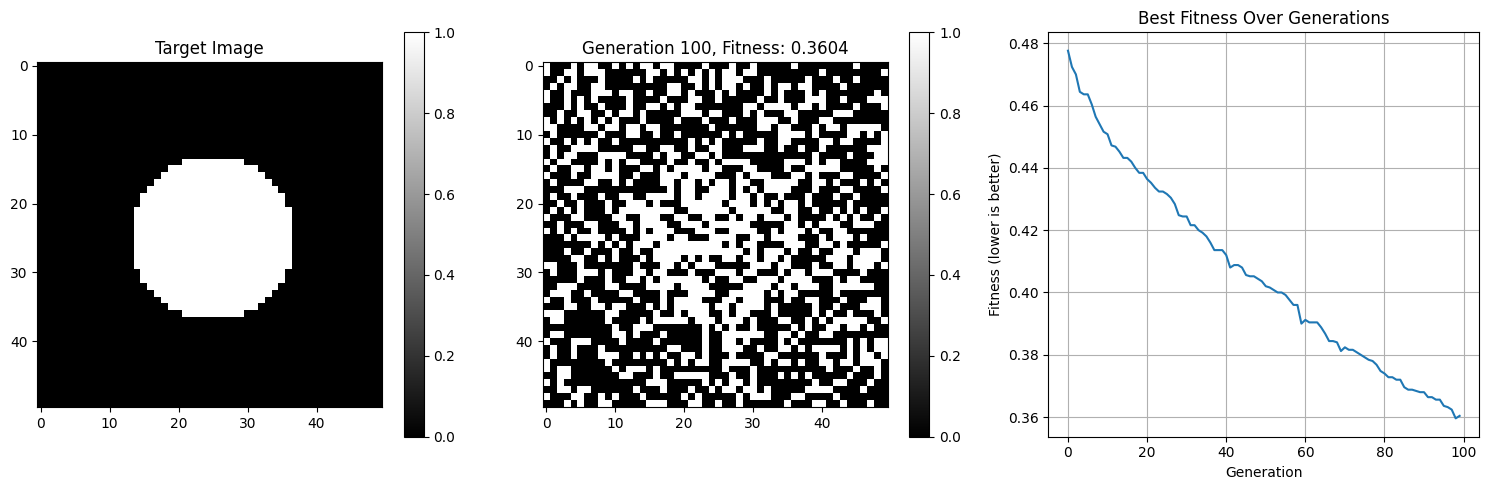

In [7]:
# Initialize fitness history tracking
plot_best_individual.fitness_history = []

# Setup statistics to track
stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register("avg", np.mean)
stats.register("std", np.std)
stats.register("min", np.min)
stats.register("max", np.max)

# Create initial population
population_size = 50
population = toolbox.population(n=population_size)

# Parameters
NGEN = 100  # Number of generations
CXPB = 0.7  # Crossover probability
MUTPB = 0.2  # Mutation probability

# Evaluate initial population
fitnesses = list(map(toolbox.evaluate, population))
for ind, fit in zip(population, fitnesses):
    ind.fitness.values = fit

# Run the algorithm with progress tracking
start_time = time.time()

for gen in range(NGEN):
    # Select the next generation individuals
    offspring = algorithms.varAnd(population, toolbox, cxpb=CXPB, mutpb=MUTPB)

    # Evaluate the individuals with an invalid fitness
    invalid_ind = [ind for ind in offspring if not ind.fitness.valid]
    fitnesses = map(toolbox.evaluate, invalid_ind)
    for ind, fit in zip(invalid_ind, fitnesses):
        ind.fitness.values = fit

    # Replace the current population with the offspring
    population = toolbox.select(offspring, k=len(population))

    # Record statistics
    record = stats.compile(population)
    print(f"Gen {gen}: Min={record['min']:.4f}, Avg={record['avg']:.4f}")

    # Track best fitness
    best_fitness = record['min']
    plot_best_individual.fitness_history.append(best_fitness)

    # Visualize progress periodically
    if gen % 10 == 0 or gen == NGEN - 1:
        plot_best_individual(population, gen, show_fitness_history=True)

# Display elapsed time
elapsed_time = time.time() - start_time
print(f"Evolution completed in {elapsed_time:.2f} seconds")

# Show final result
plot_best_individual(population, NGEN, show_fitness_history=True)

## Analyze the Evolution Process

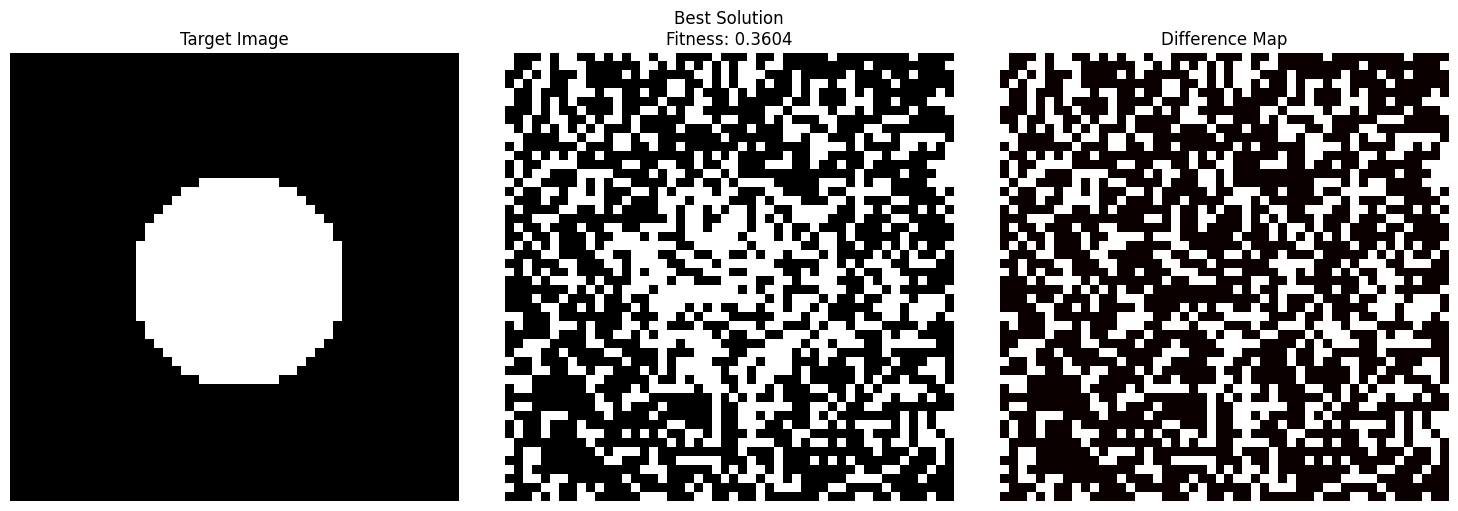

Final fitness: 0.3604
Pixel accuracy: 63.96%
Total generations: 100
Population size: 50


In [8]:
# Extract best individual
best_ind = tools.selBest(population, 1)[0]
best_fitness = best_ind.fitness.values[0]

# Calculate pixel-wise difference between best and target
difference = np.abs(best_ind - target_image)

# Display the comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(target_image, cmap='gray')
axes[0].set_title("Target Image")
axes[1].imshow(best_ind, cmap='gray')
axes[1].set_title(f"Best Solution\nFitness: {best_fitness:.4f}")
axes[2].imshow(difference, cmap='hot')
axes[2].set_title("Difference Map")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

# Print statistics
accuracy = (1 - np.sum(difference) / difference.size) * 100
print(f"Final fitness: {best_fitness:.4f}")
print(f"Pixel accuracy: {accuracy:.2f}%")
print(f"Total generations: {NGEN}")
print(f"Population size: {population_size}")